In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
import pickle

/Users/abcd/PycharmProjects/FraudShield/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
X_train = pd.read_csv("../data/splits/X_train.csv")
X_test = pd.read_csv("../data/splits/X_test.csv")
y_train = np.load("../data/splits/y_train.npy")
y_test = np.load("../data/splits/y_test.npy")

print(X_train.shape, y_train.shape)
print(X_test.shape, y_test.shape)

(227845, 32) (227845,)
(56962, 32) (56962,)


In [3]:
with open("../models/random_forest.pkl", "rb") as f:
    model = pickle.load(f)

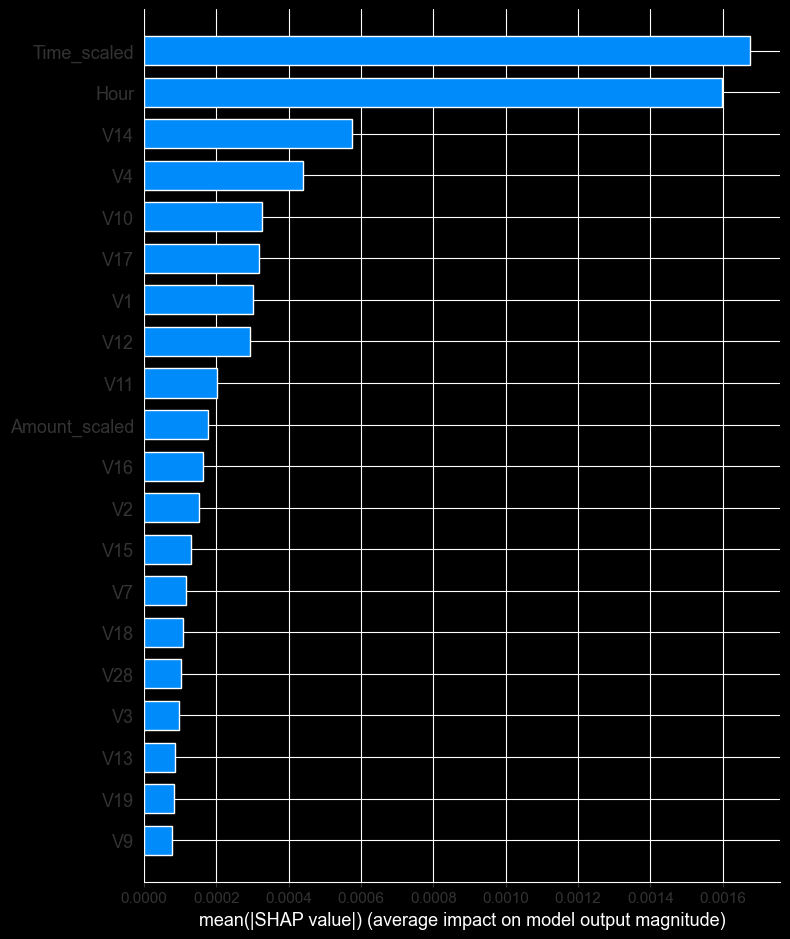

In [8]:
X_sample = X_test.sample(1000, random_state=42)
explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)
shap.summary_plot(shap_values[:, :, 1], X_sample, plot_type="bar")

In [13]:
y_sample = pd.Series(y_test, index=X_test.index)
fraud_sample = X_sample[y_sample[X_sample.index] == 1]
print(fraud_sample.shape)

(0, 32)


In [14]:
fraud_full = X_test[pd.Series(y_test, index=X_test.index) == 1]
print(fraud_full.shape)

(98, 32)


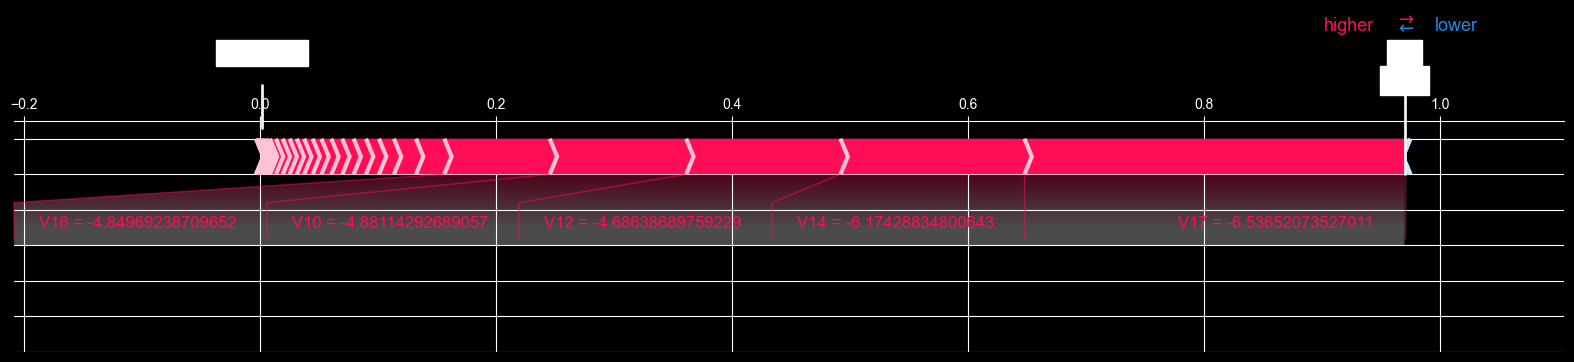

In [15]:
fraud_shap = explainer.shap_values(fraud_full.iloc[[0]])
shap.force_plot(
    explainer.expected_value[1],
    fraud_shap[:, :, 1],
    fraud_full.iloc[[0]],
    matplotlib=True
)

# Model Explainability (SHAP)

## Summary Plot (Beeswarm)
V14 shows the strongest individual impact — low values strongly push
predictions toward fraud. Time_scaled and Hour have high mean SHAP values,
suggesting the model found non-linear temporal patterns not captured by
simple correlation analysis.

## Bar Plot (Global Feature Importance)
Top features by mean absolute SHAP value:
1. Time_scaled
2. Hour
3. V14
4. V4
5. V10

## Force Plot (Single Transaction)
A confirmed fraud transaction is explained: V17=-6.5, V14=-6.2, V12=-4.7
all push strongly toward fraud prediction. Model confidence: ~100%.
This demonstrates the model correctly identifies anomalously low PCA
component values as key fraud indicators.